# EDA Samuel — `impact_load`, `threat_rank`, dan `cycle_code`

**Diagnostik awal, bukan pertanyaan final:** Seberapa kuat hubungan antara `impact_load` dan `threat_rank`, dan apakah pola deskriptifnya terlihat serupa pada periode `cycle_code` yang berbeda? Discovery lebih luas dan perbandingan TP1 ada pada notebook `02_regression_discovery.ipynb`.

Notebook ini memeriksa data regresi TP2 yang resmi, mengonfirmasi target lewat skema train–test–sample, lalu menghitung hubungan numerik dan ringkasan periode. Saat file regresi belum tersedia, notebook menampilkan status blocker dan nama file yang diperlukan. Ia tidak mengganti data regresi dengan classification.

**Batas interpretasi:** `cycle_code` diurutkan sebagai asumsi kerja untuk membentuk tiga periode berurutan. Makna domainnya perlu dikonfirmasi. Korelasi dan perbedaan distribusi bersifat deskriptif; tidak membuktikan sebab-akibat, drift, atau signifikansi statistik.

## tl;dr

**Discovery, pertanyaan belum dikunci.** Dataset regression sudah tersedia. Analisis awal menunjukkan asosiasi positif yang tidak deterministik dan perbedaan kekuatan asosiasi antarperiode. Cell berikutnya menghitung angka aktual dari data; rekomendasi kandidat ada di `reports/eda/REGRESSION_DISCOVERY.md`.

## Context & Methods

- Unit analisis: satu baris train regresi.
- Target hanya dipastikan jika `threat_rank` adalah satu-satunya kolom train-only dan sample submission berisi tepat `record_id` serta `threat_rank`.
- Pearson merangkum asosiasi linear untuk pasangan numerik finite yang bervariasi; Spearman merangkum asosiasi peringkat. Hasilnya tetap deskriptif.
- Nama `threat_rank` belum mengonfirmasi skala atau makna domainnya; pengertian tersebut tetap UNKNOWN sampai definisi resmi tersedia.
- `impact_load` dibagi ke dalam delapan bin dengan batas sama yang dihitung sekali dari train dan dipakai bersama di semua periode. Ringkasan meliputi median dan kuartil target.
- Periode membagi nilai `cycle_code` terurut menjadi tiga kelompok berukuran hampir sama, tanpa memakai target untuk menentukan batas.
- Outlier univariat ditandai sebagai nilai di luar 1.5 × IQR. Flag ini bukan alasan otomatis menghapus observasi.

## Data

File yang dicari: `data/raw/regression/Train.csv`, `Test.csv`, dan `SampleSubmission.csv`. `TP2_DATA_DIR` dapat diarahkan ke direktori lain yang berisi folder `regression/`. Data mentah dibaca saja.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src" / "utils" / "paths.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "utils" / "paths.py").is_file():
    raise FileNotFoundError("Open this notebook from the TP2 repository or a subfolder thereof.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.samuel import run_eda

report = run_eda()
print("Status:", report["status"])
print("Regression data folder:", report["input_root"])
if report["status"].startswith("BLOCKED"):
    print("Required official files:", ", ".join(report.get("missing_files", [])))
    print(report.get("next_action", ""))
else:
    print("Confirmed target:", report["target_verification"]["confirmed_target"])
    print("Train/test shapes:", report["schema"]["train_shape"], report["schema"]["test_shape"])
    print("Cycle comparison:", report["temporal"]["status"])
    if report["temporal"]["status"] != "COMPLETE":
        print("Insufficient distinct usable cycle_code values for a cross-period comparison.")


Status: COMPLETE
Regression data folder: data/raw/regression
Confirmed target: threat_rank
Train/test shapes: [50608, 19] [29421, 18]
Cycle comparison: COMPLETE


## Results

Angka, tabel, dan grafik muncul setelah cell analisis berjalan. Jika status `BLOCKED`, temuan relasi belum tersedia. Laporan agregat disimpan di `reports/eda/samuel_regression_eda.json`; grafik yang dibuat tersimpan di direktori yang sama.

### 1. Overall and period association

In [2]:

if report["status"] == "COMPLETE":
    rows = [{"group": "all", **report["relationship"]["overall"]}]
    rows.extend({"group": row["period"], **row} for row in report["relationship"]["by_period"])
    display(pd.DataFrame(rows)[["group", "n_complete", "pearson_r", "spearman_rho"]])
    print("Exact repeated impact_load check:")
    display(pd.DataFrame([report["relationship"]["exact_impact_repeat_audit"]]))
    print("Per-cycle correlations:")
    if report["relationship"]["by_cycle"]:
        display(pd.DataFrame(report["relationship"]["by_cycle"])[
            ["cycle_code", "n_complete", "pearson_r", "spearman_rho", "target_nonmissing_n"]])
    else:
        print("No usable cycle_code groups are available.")
else:
    print("No target-feature association can be reported until the official regression data is available.")


,group,n_complete,pearson_r,spearman_rho
0,all,50608,0.637017,0.621102
1,period_01,13546,0.499393,0.477280
2,period_02,16736,0.672178,0.663114
3,period_03,20326,0.696391,0.679783


Exact repeated impact_load check:


,unique_impact_values_with_complete_pairs,impact_values_repeated,repeated_impact_values_with_multiple_targets,exactly_determined_on_repeated_impact_values
0,80,78,77,False


Per-cycle correlations:


,cycle_code,n_complete,pearson_r,spearman_rho,target_nonmissing_n
0,47,1342,0.448749,0.414756,1342
1,48,977,0.512329,0.484361,977
2,49,1255,0.454090,0.428351,1255
3,50,1111,0.490400,0.473701,1111
4,51,1535,0.548199,0.534340,1535
5,52,1565,0.475592,0.453428,1565
6,53,1371,0.480489,0.440646,1371
7,54,1256,0.514711,0.493950,1256
8,55,1608,0.447169,0.438604,1608
9,56,564,0.651070,0.634399,564


### 2. Relationship shape and conditional spread

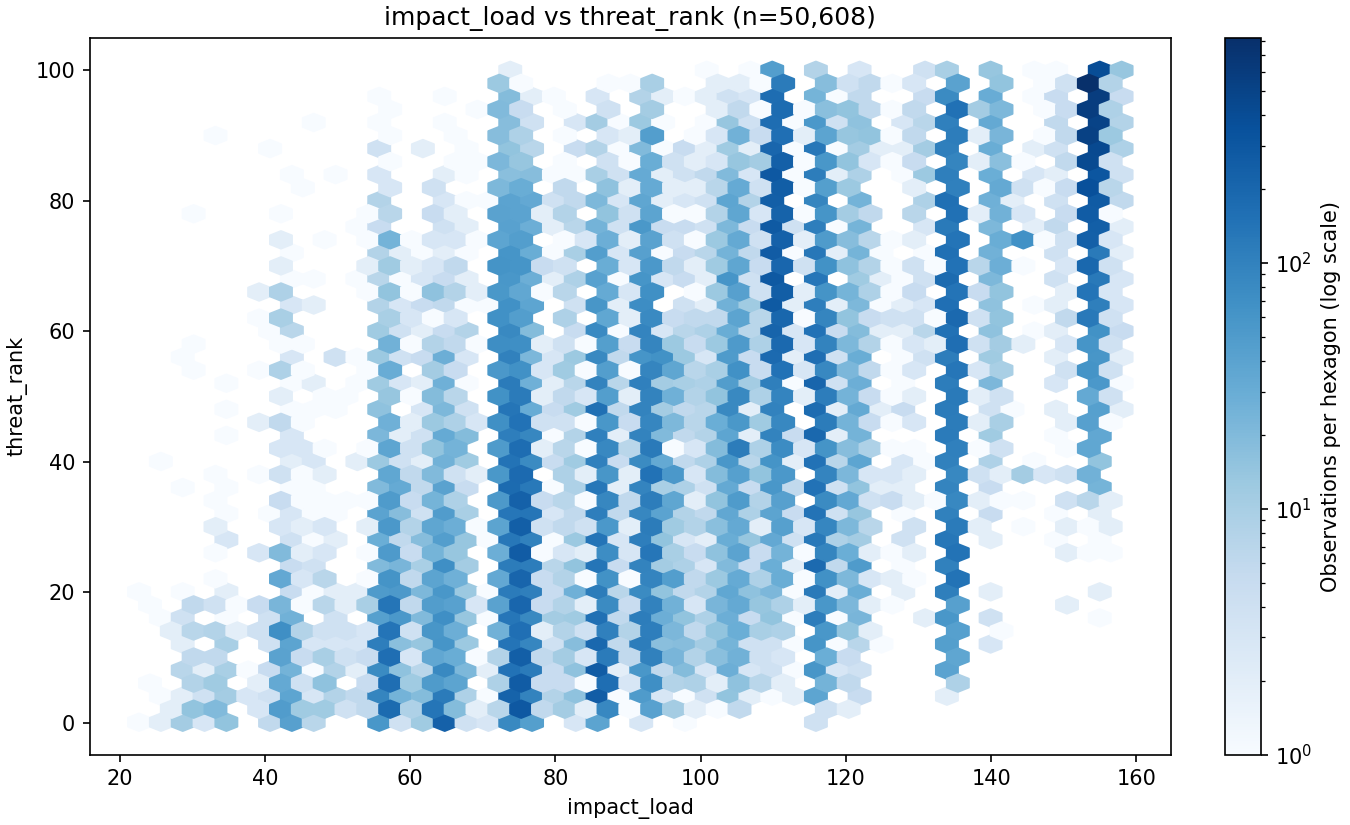

In [3]:

if report["status"] == "COMPLETE":
    figure = PROJECT_ROOT / "reports" / "eda" / "samuel_impact_threat_hexbin.png"
    if figure.is_file():
        display(Image(filename=str(figure)))


,period,impact_bin,n_complete_pairs,threat_rank_median,threat_rank_q25,threat_rank_q75
0,period_01,"(22.645999999999997, 39.563]",79,8.39550,0.906100,20.622900
1,period_01,"(39.563, 56.478]",258,14.53900,2.933125,48.643775
2,period_01,"(56.478, 73.394]",1602,32.58715,13.713325,55.883500
3,period_01,"(73.394, 90.31]",2932,32.03255,12.525500,52.866875
4,period_01,"(90.31, 107.225]",1894,39.51615,18.967475,63.328950
5,period_01,"(107.225, 124.141]",3550,58.73760,35.913900,81.028800
6,period_01,"(124.141, 141.057]",1618,61.47390,41.359100,80.761200
7,period_01,"(141.057, 157.972]",1613,83.01040,67.436700,94.403000
8,period_02,"(22.645999999999997, 39.563]",89,6.08930,2.300400,8.884800
9,period_02,"(39.563, 56.478]",287,11.39710,5.134900,14.843350


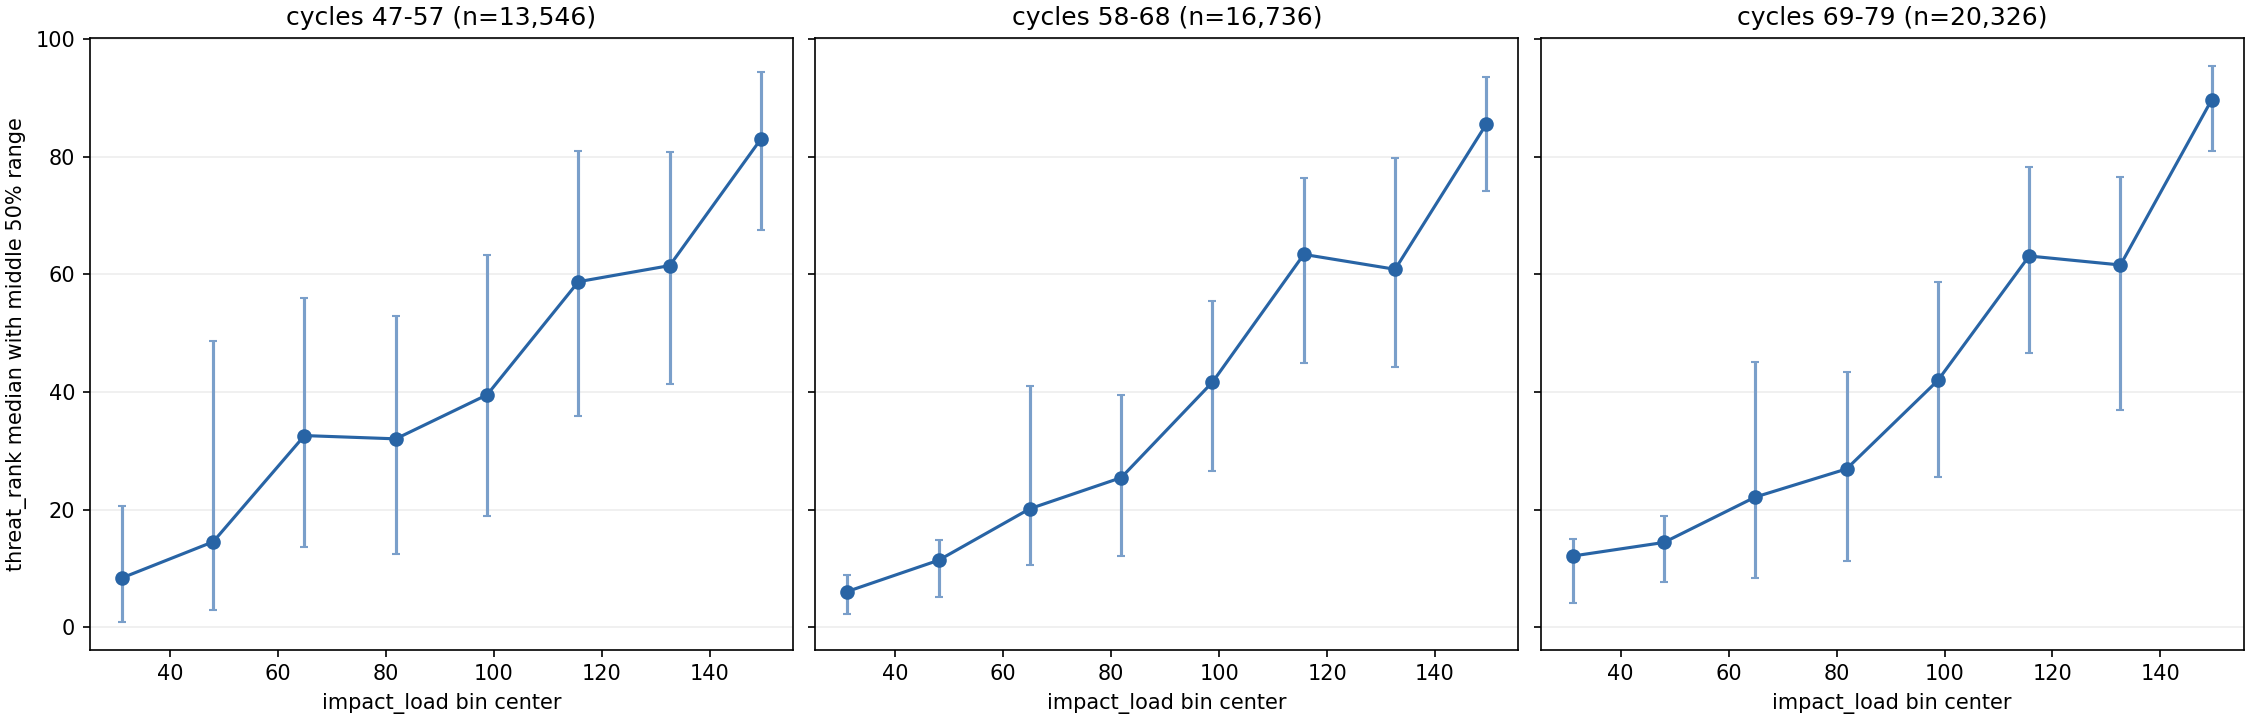

In [4]:

if report["status"] == "COMPLETE":
    display(pd.DataFrame(report["relationship"]["by_period_and_impact_bin"]))
    figure = PROJECT_ROOT / "reports" / "eda" / "samuel_impact_bins_by_period.png"
    if figure.is_file():
        display(Image(filename=str(figure)))


### 3. Target distribution by period

,label,n,median,q25,q75,impact_load_median
0,period_01,13546,50.03225,25.104000,75.023200,108.7033
1,period_02,16736,50.01280,25.054425,74.907100,110.5078
2,period_03,20326,50.03845,25.024375,75.021175,106.9066


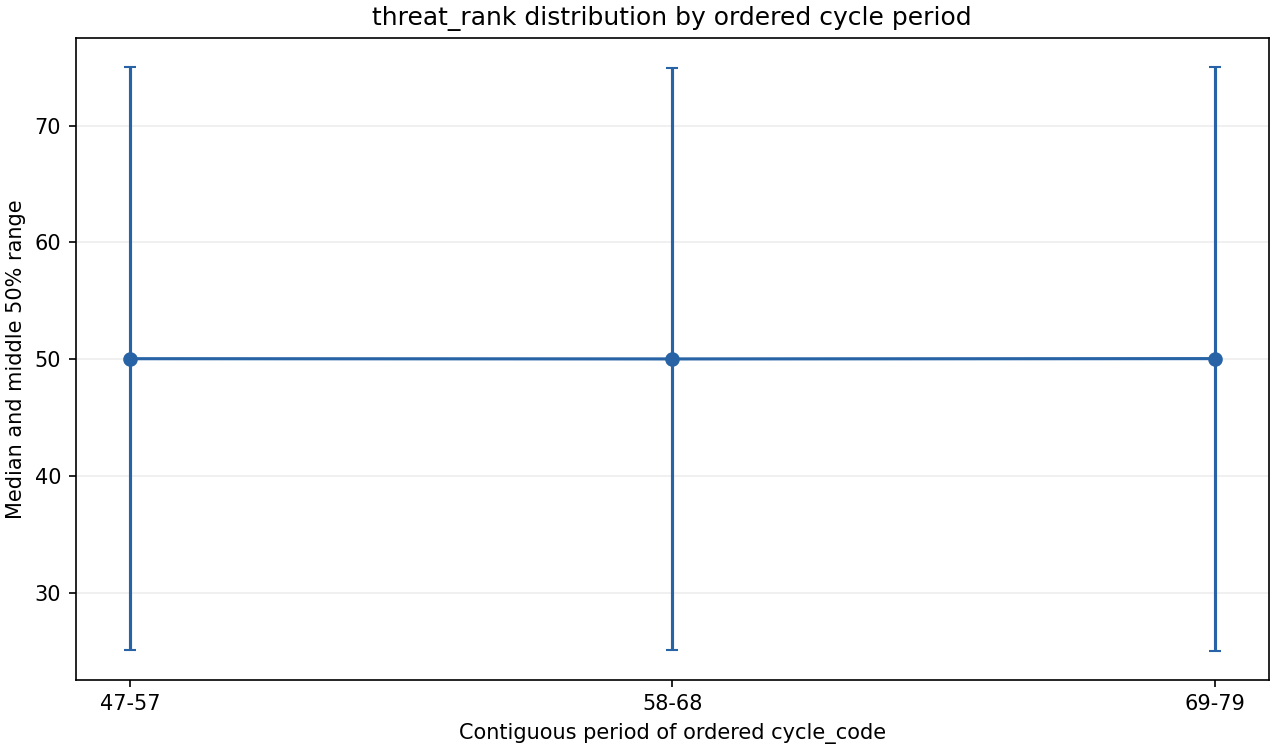

In [5]:

if report["status"] == "COMPLETE":
    display(pd.DataFrame(report["temporal"]["period_target_distribution"]))
    figure = PROJECT_ROOT / "reports" / "eda" / "samuel_threat_by_period.png"
    if figure.is_file():
        display(Image(filename=str(figure)))


## Takeaways

Tafsirkan arah dan kekuatan korelasi bersama bentuk sebaran serta variasi `threat_rank` pada nilai `impact_load` serupa. Bandingkan periode dengan batas bin `impact_load` yang sama dan periksa ukuran kelompok. Perbedaan deskriptif hanya menjadi indikasi untuk pemeriksaan lanjutan; jangan menyebutnya drift atau efek fitur tanpa bukti tambahan.